# 02 · Bag-of-Words vs TF-IDF (Module II)

**Theory.** Both turn a document into a vector with one column per vocabulary term.
*Bag-of-Words* stores raw counts, so frequent but uninformative words ("say", "new") dominate.
*TF-IDF* multiplies each count by the inverse document frequency,
`idf(t) = ln((1+n)/(1+df(t))) + 1`, which shrinks terms that appear in many documents and boosts
rare, distinctive ones. It then scales each row to length 1, so long and short documents are comparable.
Both ignore word order; adding *bigrams* ("oil price", "world cup") puts a little local order back.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer as SkTfidf
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src.utils import FAST, MODELS, SEED
from src.data import AG_LABELS, load
from src.preprocess import clean
from src.tfidf import BagOfWords, TfidfVectorizer
from src.evaluate import classification_metrics, plot_confusion, save_results, size_mb

pd.set_option("display.max_colwidth", 80)
print("FAST mode:", FAST)

FAST mode: False


## Part A · From-scratch BoW and TF-IDF on a 5-document toy corpus
`src/tfidf.py` (69 lines). Documents are already tokenized, so a term is a space-separated word.

In [2]:
toy = ["stocks fall as oil prices rise",
       "oil prices rise again",
       "team wins the cup final",
       "stocks rise after team sponsor deal",
       "the final deal on oil"]

bow = BagOfWords().fit(toy)
pd.DataFrame(bow.transform(toy).toarray().astype(int), columns=bow.get_feature_names_out(),
             index=[f"d{i}" for i in range(5)])

,after,again,as,cup,deal,fall,final,oil,on,prices,rise,sponsor,stocks,team,the,wins
d0,0,0,1,0,0,1,0,1,0,1,1,0,1,0,0,0
d1,0,1,0,0,0,0,0,1,0,1,1,0,0,0,0,0
d2,0,0,0,1,0,0,1,0,0,0,0,0,0,1,1,1
d3,1,0,0,0,1,0,0,0,0,0,1,1,1,1,0,0
d4,0,0,0,0,1,0,1,1,1,0,0,0,0,0,1,0


In [3]:
tfidf = TfidfVectorizer().fit(toy)
pd.DataFrame({"df": tfidf.df_, "idf": tfidf.idf_.round(3)}, index=tfidf.get_feature_names_out()).T

,after,again,as,cup,deal,fall,final,oil,on,prices,rise,sponsor,stocks,team,the,wins
df,1.000,1.000,1.000,1.000,2.000,1.000,2.000,3.000,1.000,2.000,3.000,1.000,2.000,2.000,2.000,1.000
idf,2.099,2.099,2.099,2.099,1.693,2.099,1.693,1.405,2.099,1.693,1.405,2.099,1.693,1.693,1.693,2.099


In [4]:
X_ours = tfidf.transform(toy).toarray()
pd.DataFrame(X_ours.round(3), columns=tfidf.get_feature_names_out(), index=[f"d{i}" for i in range(5)])

,after,again,as,cup,deal,fall,final,oil,on,prices,rise,sponsor,stocks,team,the,wins
d0,0.000,0.000,0.488,0.000,0.000,0.488,0.000,0.327,0.000,0.394,0.327,0.000,0.394,0.000,0.000,0.000
d1,0.000,0.626,0.000,0.000,0.000,0.000,0.000,0.420,0.000,0.505,0.420,0.000,0.000,0.000,0.000,0.000
d2,0.000,0.000,0.000,0.503,0.000,0.000,0.406,0.000,0.000,0.000,0.000,0.000,0.000,0.406,0.406,0.503
d3,0.477,0.000,0.000,0.000,0.385,0.000,0.000,0.000,0.000,0.000,0.319,0.477,0.385,0.385,0.000,0.000
d4,0.000,0.000,0.000,0.000,0.437,0.000,0.437,0.363,0.542,0.000,0.000,0.000,0.000,0.000,0.437,0.000


**One cell by hand:** "oil" in d1 = "oil prices rise again". Here tf = 1, df(oil) = 3 and n = 5,
so idf = ln(6/4) + 1 = 1.405. d1's four words have idf 1.405 (oil), 1.693 (prices),
1.405 (rise) and 2.099 (again). Row length = √(1.405² + 1.693² + 1.405² + 2.099²).

In [5]:
idf = dict(zip(tfidf.get_feature_names_out(), tfidf.idf_))
length = np.sqrt(sum(idf[w] ** 2 for w in "oil prices rise again".split()))
print(f"idf(oil) = {idf['oil']:.4f}, row length = {length:.4f}, "
      f"tfidf(oil, d1) = {idf['oil'] / length:.4f}, ours = {X_ours[1, tfidf.vocabulary_['oil']]:.4f}")

idf(oil) = 1.4055, row length = 3.3499, tfidf(oil, d1) = 0.4196, ours = 0.4196


**Check against sklearn.** Same tokens (`tokenizer=str.split`), default smoothing and L2 norm:

In [6]:
SK = dict(tokenizer=str.split, lowercase=False, token_pattern=None)
for ngr in [(1, 1), (1, 2)]:
    sk_bow = CountVectorizer(ngram_range=ngr, **SK).fit_transform(toy).toarray()
    sk_tfidf = SkTfidf(ngram_range=ngr, **SK).fit_transform(toy).toarray()
    assert np.allclose(BagOfWords(ngram_range=ngr).fit_transform(toy).toarray(), sk_bow)
    assert np.allclose(TfidfVectorizer(ngram_range=ngr).fit_transform(toy).toarray(), sk_tfidf)
    print(f"ngram_range={ngr}: BoW and TF-IDF match sklearn (np.allclose)")

ngram_range=(1, 1): BoW and TF-IDF match sklearn (np.allclose)
ngram_range=(1, 2): BoW and TF-IDF match sklearn (np.allclose)


## Part B · AG News classification
Every model: `clean(mode="news")` text → vectorizer → the same `LogisticRegression`.
30,000 training rows, full 7,600-row test set. `min_df=2` drops terms seen in only one document.
The *main* configuration (unigrams + bigrams) is fixed in advance, not picked by test score.

In [7]:
train, test = load("ag_train"), load("ag_test")
t0 = time.perf_counter()
X_train_txt = [clean(t) for t in train.text]
t1 = time.perf_counter()
X_test_txt = [clean(t) for t in test.text]
clean_ms_per_doc = (time.perf_counter() - t1) / len(test) * 1000
print(f"cleaned {len(train):,} train docs in {t1 - t0:.1f}s; test cleaning = {clean_ms_per_doc:.2f} ms/doc")

cleaned 30,000 train docs in 17.3s; test cleaning = 0.56 ms/doc


Our vectorizer on real data: identical to sklearn on the first 2,000 training documents.

In [8]:
sub = X_train_txt[:2000]
t = time.perf_counter(); ours = TfidfVectorizer(ngram_range=(1, 2), min_df=2).fit_transform(sub); t_ours = time.perf_counter() - t
t = time.perf_counter(); sk = SkTfidf(ngram_range=(1, 2), min_df=2, **SK).fit_transform(sub); t_sk = time.perf_counter() - t
print("shape", ours.shape, "| allclose:", np.allclose(ours.toarray(), sk.toarray()),
      f"| ours {t_ours:.2f}s vs sklearn {t_sk:.2f}s")

shape (2000, 7128) | allclose: True | ours 0.04s vs sklearn 0.03s


In [9]:
configs = {
    "BoW unigram": CountVectorizer(ngram_range=(1, 1), min_df=2, **SK),
    "BoW uni+bigram": CountVectorizer(ngram_range=(1, 2), min_df=2, **SK),
    "TF-IDF unigram": SkTfidf(ngram_range=(1, 1), min_df=2, **SK),
    "TF-IDF uni+bigram": SkTfidf(ngram_range=(1, 2), min_df=2, **SK),
}
rows, fitted = [], {}
for name, vec in configs.items():
    pipe = Pipeline([("vec", vec), ("clf", LogisticRegression(max_iter=2000, random_state=SEED))])
    t = time.perf_counter(); pipe.fit(X_train_txt, train.label); train_s = time.perf_counter() - t
    t = time.perf_counter(); pred = pipe.predict(X_test_txt); pred_s = time.perf_counter() - t
    m = classification_metrics(test.label, pred, AG_LABELS)
    fitted[name] = (pipe, pred, m, train_s, pred_s)
    rows.append({"model": name, "accuracy": m["accuracy"], "macro_P": m["macro_precision"],
                 "macro_R": m["macro_recall"], "macro_F1": m["macro_f1"],
                 "vocab": len(pipe["vec"].vocabulary_), "train_s": round(train_s, 1),
                 "infer_ms/doc (incl. clean)": round(pred_s / len(test) * 1000 + clean_ms_per_doc, 3),
                 "size_MB": size_mb(pipe)})
table = pd.DataFrame(rows).set_index("model")
table

,accuracy,macro_P,macro_R,macro_F1,vocab,train_s,infer_ms/doc (incl. clean),size_MB
model,,,,,,,,
BoW unigram,0.8832,0.8828,0.8832,0.8829,21326,0.7,0.560,0.96
BoW uni+bigram,0.8982,0.8979,0.8982,0.8979,107993,2.1,0.568,5.42
TF-IDF unigram,0.9009,0.9005,0.9009,0.9006,21326,0.9,0.561,1.13
TF-IDF uni+bigram,0.9018,0.9014,0.9018,0.9015,107993,2.5,0.569,6.28


## Is the TF-IDF vs BoW gap real? Paired bootstrap on the test set
Resample the 7,600 test documents with replacement 1,000 times. Each time, compute
accuracy(A) − accuracy(B) on the *same* resampled documents. If the 95% interval contains 0,
this test set cannot separate the two models.

In [10]:
rng = np.random.default_rng(SEED)
y = test.label.to_numpy()

def paired_bootstrap(pred_a, pred_b, n_boot=1000):
    a, b = (pred_a == y), (pred_b == y)                  # True where each model is right
    idx = rng.integers(0, len(y), size=(n_boot, len(y)))  # 1,000 resampled test sets
    diffs = a[idx].mean(axis=1) - b[idx].mean(axis=1)
    return a.mean() - b.mean(), np.percentile(diffs, [2.5, 97.5])

boot = {}
for a, b in [("TF-IDF unigram", "BoW unigram"), ("TF-IDF uni+bigram", "BoW uni+bigram"),
             ("BoW uni+bigram", "BoW unigram"), ("TF-IDF uni+bigram", "TF-IDF unigram")]:
    diff, (lo, hi) = paired_bootstrap(fitted[a][1], fitted[b][1])
    boot[f"{a} - {b}"] = {"acc_diff": round(diff, 4), "ci95": [round(lo, 4), round(hi, 4)]}
    print(f"{a:18s} - {b:15s}: {diff:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]"
          f"  -> {'real difference' if lo > 0 or hi < 0 else 'not distinguishable'}")

TF-IDF unigram     - BoW unigram    : +0.0178  95% CI [+0.0130, +0.0228]  -> real difference
TF-IDF uni+bigram  - BoW uni+bigram : +0.0037  95% CI [-0.0007, +0.0076]  -> not distinguishable
BoW uni+bigram     - BoW unigram    : +0.0150  95% CI [+0.0105, +0.0193]  -> real difference
TF-IDF uni+bigram  - TF-IDF unigram : +0.0009  95% CI [-0.0020, +0.0038]  -> not distinguishable


**Reading.** With unigrams, TF-IDF clearly beats raw counts. Bigrams give BoW a large boost but
add little to TF-IDF, so at uni+bigram the two cannot be told apart on this test set.
(This interval only covers test-set noise. A different 30k training sample moves accuracy too.)

## Top-10 features per class (TF-IDF uni+bigram)
The largest logistic-regression weights for each class: the terms that push a document towards it.
Watch for **news-agency names** (*afp*, *canadian press*, *cbs.mw*, *reuters reuters*): the model partly
learns *who wrote* the story, not only what it is about. That cue would not transfer to other sources.

In [11]:
def top_features(pipe, k=10):
    names = pipe["vec"].get_feature_names_out()
    return pd.DataFrame({AG_LABELS[c]: names[np.argsort(pipe["clf"].coef_[c])[::-1][:k]]
                         for c in range(len(AG_LABELS))})

top_features(fitted["TF-IDF uni+bigram"][0])

,World,Sports,Business,Sci/Tech
0,iraq,team,company,internet
1,afp,coach,oil,microsoft
2,kill,sport,airline,space
3,president,season,inc.,software
4,iraqi,cup,bank,nasa
5,leader,player,profit,scientist
6,nuclear,league,sale,web
7,election,game,us,computer
8,bomb,win,corp.,apple
9,iran,olympic,retailer,technology


Same for BoW uni+bigram, for comparison:

In [12]:
top_features(fitted["BoW uni+bigram"][0])

,World,Sports,Business,Sci/Tech
0,canadian press,sport,retailer,nasa
1,iraqi,coach,finance,scientist
2,bomb,club,airline,hp
3,afp,cup,tax,apple
4,arafat,team,cbs.mw,internet
5,athens greece,stadium,insurance,space
6,nuclear,player,economy,science
7,baghdad,championship,google desktop,web
8,iraq,baseball,vioxx,software
9,military,league,martha,microsoft


## Confusion matrices (main configurations)

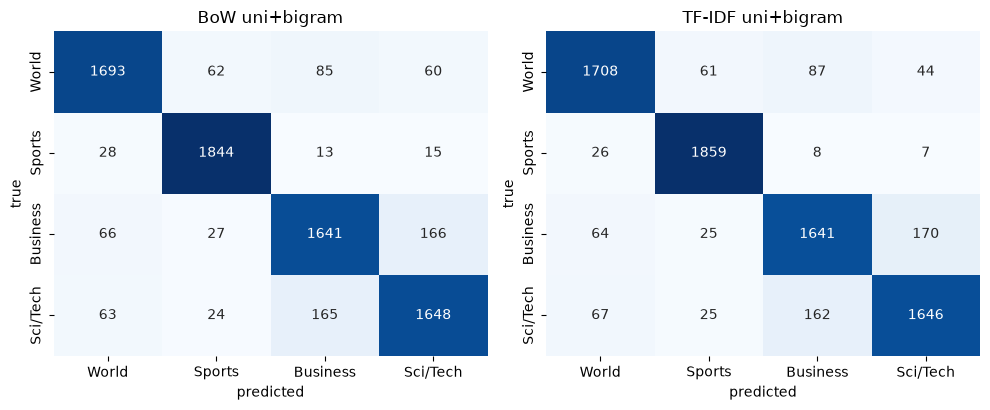

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, name in zip(axes, ["BoW uni+bigram", "TF-IDF uni+bigram"]):
    plot_confusion(test.label, fitted[name][1], AG_LABELS, ax=ax, title=name)
plt.tight_layout(); plt.show()

## Save results and the API model
`results/bow.json` and `results/tfidf.json` hold the main (uni+bigram) configuration plus all
variants. The TF-IDF pipeline is saved for the REST API (`api/app.py`, which calls `clean()` first).

In [14]:
for family, main in [("bow", "BoW uni+bigram"), ("tfidf", "TF-IDF uni+bigram")]:
    pipe, pred, m, train_s, pred_s = fitted[main]
    save_results(family, {
        "dataset": "ag_news", "n_train": len(train), "n_test": len(test), "config": main,
        "metrics": m, "vocab_size": len(pipe["vec"].vocabulary_),
        "train_time_s": round(train_s, 2),
        "infer_ms_per_doc": round(pred_s / len(test) * 1000 + clean_ms_per_doc, 3),
        "model_size_mb": size_mb(pipe),
        "bootstrap_vs_other": boot,
        "variants": table[table.index.str.startswith(main.split()[0])].reset_index().to_dict("records"),
        "y_pred": pred,
    })

if not FAST:
    MODELS.mkdir(exist_ok=True)
    joblib.dump(fitted["TF-IDF uni+bigram"][0], MODELS / "tfidf_lr.joblib")
    print("saved models/tfidf_lr.joblib")

saved results/bow.json
saved results/tfidf.json
saved models/tfidf_lr.joblib


## Viva notes
**Q1. Write the TF-IDF formula that sklearn uses.**
`tfidf(t,d) = count(t,d) × idf(t)` with `idf(t) = ln((1+n)/(1+df(t))) + 1`, then each row is divided by
its L2 length. The +1 terms prevent division by zero and keep common words from getting weight 0.
`src/tfidf.py` reproduces this and `np.allclose` confirms it equals sklearn.

**Q2. Why can TF-IDF beat raw counts with the same classifier?**
Counts let frequent, uninformative words dominate the vector, and long documents get large vectors.
IDF down-weights words that appear everywhere, and L2 normalisation removes the length effect.
On AG News the gap is small: the bootstrap cell above shows whether it is larger than the noise.
Logistic regression can learn small weights for useless words itself, and AG texts are short
(median 37 words), so length normalisation matters less.

**Q3. What do bigrams add, and what do they cost?**
They capture short phrases ("oil price", "world cup", "prime minister") that single words miss.
The cost is a much larger, sparser vocabulary (compare the `vocab` column): more memory and more
features seen only a few times.